In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

from dlfs.helpers import DLFSData

# Binary MNIST classification

In [2]:
mnist_path = "../data/mnist"

X_train, y_train, X_test, y_test = DLFSData.MNIST.load_MNIST(mnist_path)

print(f'X_train: {X_train.shape}, y_train: {y_train.shape}')
print(f'X_test: {X_test.shape}, y_test: {y_test.shape}')

X_train: (60000, 28, 28), y_train: (60000,)
X_test: (10000, 28, 28), y_test: (10000,)


In [3]:
X_train = DLFSData.normalize_images(X_train, range=(0, 1))
X_test = DLFSData.normalize_images(X_test, range=(0, 1))

X_train, y_train = DLFSData.select_image_labels(X_train, y_train, labels=[0, 1], limit=100)
X_test, y_test = DLFSData.select_image_labels(X_test, y_test, labels=[0, 1], limit=100)

X_train, X_test = X_train.reshape(-1, 1, 28, 28), X_test.reshape(-1, 1, 28, 28)

print(f'X_train: {X_train.shape}, y_train: {y_train.shape}')
print(f'X_test: {X_test.shape}, y_test: {y_test.shape}')

X_train: (200, 1, 28, 28), y_train: (200,)
X_test: (200, 1, 28, 28), y_test: (200,)


In [4]:
from dlfs_autograd.layers import DenseLayer, ConvLayer, MaxPoolLayer, ReshapeLayer
from dlfs_autograd.activation import Sigmoid, ReLU
from dlfs_autograd.loss import BCE_Loss
from dlfs_autograd.optimizer import Optimizer_SGD, Optimizer_Adam
from dlfs_autograd.model import SequentialModel

layers = [ConvLayer(input_channels=1, output_channels=3, kernel_size=2, padding=1, stride=2),
          MaxPoolLayer(pool_size=3, stride=2), 
          ReshapeLayer(input_shape=(3, 7, 7), output_shape=(3*7*7, )),
          DenseLayer(3*7*7, 100),
          Sigmoid(),
          DenseLayer(100, 1),
          Sigmoid()]

model = SequentialModel(layers=layers, loss_function=BCE_Loss(), optimizer=Optimizer_Adam(learning_rate=1e-2))

model.train(X_train, y_train.reshape(-1, 1), print_every=10, epochs=30)

===== EPOCH : 0 ===== LOSS : 0.6859190464019775 =====
===== EPOCH : 10 ===== LOSS : 0.16463595628738403 =====
===== EPOCH : 20 ===== LOSS : 0.03586829453706741 =====
===== EPOCH : 30 ===== LOSS : 0.009756406769156456 =====


In [5]:
y_pred = model.predict(X_test)
print(f'Model accuracy: {np.mean(np.round(y_pred) == y_test.reshape(-1, 1))}')

Model accuracy: 0.99


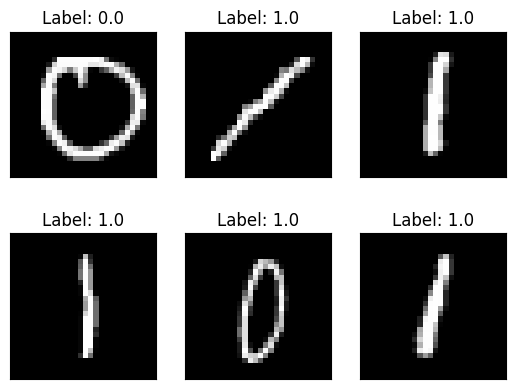

In [6]:
fig, ax = plt.subplots(nrows=2, ncols=3)
i, j = 0, 0

np.random.shuffle(X_test)

for idx, x in enumerate(X_test[:6]):

    img = x.reshape(28, 28)
    x = x.reshape(1, *x.shape)
    y_pred = model.predict(x)

    ax[i, j].imshow(img, cmap='gray')
    ax[i, j].set_xticks([])
    ax[i, j].set_yticks([])
    ax[i, j].set_title(f'Label: {np.round(y_pred[0, 0])}')

    j += 1
    if j % 3 == 0:
        i += 1
        j = 0

plt.show()

# Visualization of kernels learned

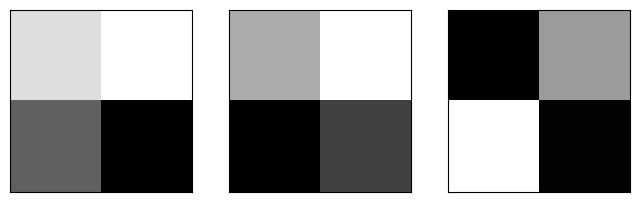

In [7]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(8, 8))

conv = model.wrapper.layers[0]
kernel = conv.kernels.data.reshape(
    conv.output_channels, 
    conv.input_channels, 
    conv.kernel_size, 
    conv.kernel_size
)

for i in range(conv.output_channels):
    for j in range(conv.input_channels):

        x = kernel[i, j]
        ax[i].imshow(x, cmap='gray')
        ax[i].set_xticks([])
        ax[i].set_yticks([])

plt.show()

# MNIST classification

In [8]:
def one_hot_encode(y):
    categories = np.unique(y)
    encoded_y = np.zeros((len(y), len(categories)))

    for idx, label in enumerate(y):
        to_encode_idx = np.argwhere(categories == label)
        encoded_y[idx, to_encode_idx] = 1

    return encoded_y

X_train, y_train, X_test, y_test = DLFSData.MNIST.load_MNIST(mnist_path)

X_train = DLFSData.normalize_images(X_train[:10000], range=(0, 1))
X_test = DLFSData.normalize_images(X_test[:1000], range=(0, 1))

X_train, X_test = X_train.reshape(-1, 1, 28, 28), X_test.reshape(-1, 1, 28, 28)

y_train = one_hot_encode(y_train[:10000])
y_test = one_hot_encode(y_test[:1000])

print(f'X_train: {X_train.shape}, y_train: {y_train.shape}')
print(f'X_test: {X_test.shape}, y_test: {y_test.shape}')

X_train: (10000, 1, 28, 28), y_train: (10000, 10)
X_test: (1000, 1, 28, 28), y_test: (1000, 10)


In [9]:
from dlfs_autograd.activation import Softmax
from dlfs_autograd.loss import CCE_Loss

layers = [ConvLayer(input_channels=1, output_channels=3, kernel_size=3, stride=1, padding=1),
          ReLU(),
          ConvLayer(input_channels=3, output_channels=6, kernel_size=3, stride=1, padding=1),
          ReLU(),
          MaxPoolLayer(pool_size=2, stride=2, padding=0), 
          MaxPoolLayer(pool_size=2, stride=2, padding=0),
          ReshapeLayer(input_shape=(6, 7, 7), output_shape=(6 * 7 * 7, )),
          DenseLayer(6 * 7 * 7, 128),
          ReLU(),
          DenseLayer(128, 10),
          Softmax()]

model = SequentialModel(layers=layers, loss_function=CCE_Loss(from_logits=False), optimizer=Optimizer_Adam(learning_rate=1e-2))

model.train(X_train, y_train, print_every=10, epochs=100)

===== EPOCH : 0 ===== LOSS : 2.3027265071868896 =====
===== EPOCH : 10 ===== LOSS : 0.7216358780860901 =====
===== EPOCH : 20 ===== LOSS : 0.35063448548316956 =====
===== EPOCH : 30 ===== LOSS : 0.2232692390680313 =====
===== EPOCH : 40 ===== LOSS : 0.15090690553188324 =====
===== EPOCH : 50 ===== LOSS : 0.11104753613471985 =====
===== EPOCH : 60 ===== LOSS : 0.0840650349855423 =====
===== EPOCH : 70 ===== LOSS : 0.06560011953115463 =====
===== EPOCH : 80 ===== LOSS : 0.051869068294763565 =====
===== EPOCH : 90 ===== LOSS : 0.041279230266809464 =====
===== EPOCH : 100 ===== LOSS : 0.03306543081998825 =====


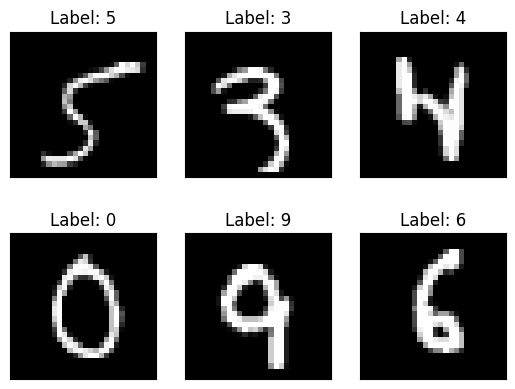

In [12]:
fig, ax = plt.subplots(nrows=2, ncols=3)
i, j = 0, 0

np.random.shuffle(X_test)

for idx, x in enumerate(X_test[:6]):

    img = x.reshape(28, 28)
    x = x.reshape(1, *x.shape)
    y_pred = model.predict(x)

    ax[i, j].imshow(img, cmap='gray')
    ax[i, j].set_xticks([])
    ax[i, j].set_yticks([])
    ax[i, j].set_title(f'Label: {np.argmax(y_pred.reshape(-1))}')

    j += 1
    if j % 3 == 0:
        i += 1
        j = 0

plt.show()